# Работа с библиотекой Pandas

* Добавлены диаграммы (через pandas): гистограмма, точечный/линейный график

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

1. Загрузите набор данных из файла **car_data.csv** по примеру с лекции


In [2]:
df = pd.read_csv('car_data.csv')

# Убираем служебный столбец-индекс (первый безымянный столбец)
if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
    df = df.drop(columns=df.columns[0])

print("Размер исходного датафрейма:", df.shape)
df.head()

Размер исходного датафрейма: (5001, 16)


,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
0,C_CND_000001,1/2/2022,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,DoubleÂ Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown
1,C_CND_000002,1/2/2022,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,DoubleÂ Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora
2,C_CND_000003,1/2/2022,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville
3,C_CND_000004,1/2/2022,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco
4,C_CND_000005,1/2/2022,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,DoubleÂ Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville


2. Проведите анализ пропусков в данных. Удалите строки или столбцы, содержащие пропуски.

In [3]:
print("Пропуски по столбцам (до очистки):")
print(df.isna().sum())

print("\nДоля пропусков по столбцам:")
print(df.isna().mean().round(4))

# Удаляем столбцы, где пропусков слишком много (например, > 50%)
threshold = 0.5
cols_to_drop = df.columns[df.isna().mean() > threshold]
df = df.drop(columns=cols_to_drop)
print("\nУдалены столбцы с долей пропусков > 50%:", list(cols_to_drop))

# Удаляем строки, содержащие хотя бы один пропуск
df = df.dropna()
print("Размер датафрейма после удаления пропусков:", df.shape)

Пропуски по столбцам (до очистки):
Car_id            0
Date              0
Customer Name     0
Gender            0
Annual Income     0
Dealer_Name      72
Company          72
Model             0
Engine            0
Transmission      0
Color             0
Price ($)         0
Dealer_No         0
Body Style        0
Phone             0
Dealer_Region     0
dtype: int64

Доля пропусков по столбцам:
Car_id           0.0000
Date             0.0000
Customer Name    0.0000
Gender           0.0000
Annual Income    0.0000
Dealer_Name      0.0144
Company          0.0144
Model            0.0000
Engine           0.0000
Transmission     0.0000
Color            0.0000
Price ($)        0.0000
Dealer_No        0.0000
Body Style       0.0000
Phone            0.0000
Dealer_Region    0.0000
dtype: float64

Удалены столбцы с долей пропусков > 50%: []
Размер датафрейма после удаления пропусков: (4929, 16)


3. Вычислите средний доход клиентов, купивших автомобиль марки Toyota Camry.

In [4]:
camry_income = df.loc[
    (df['Company'] == 'Toyota') & (df['Model'] == 'Camry'),
    'Annual Income'
].mean()

print("Средний доход клиентов, купивших Toyota Camry:", camry_income)

Средний доход клиентов, купивших Toyota Camry: 776609.375


4. Найдите топ 10 самых дорогих марок автомобилей за представленный период времени.


Топ-10 самых дорогих марок автомобилей (по средней цене):
Company
Cadillac      41124.325203
Saab          40941.048780
Lincoln       32987.953271
Lexus         32930.897436
Buick         31560.687500
Oldsmobile    31387.188034
Plymouth      30604.331169
Saturn        30531.367188
Toyota        30415.163717
Pontiac       29635.026738
Name: Price ($), dtype: float64


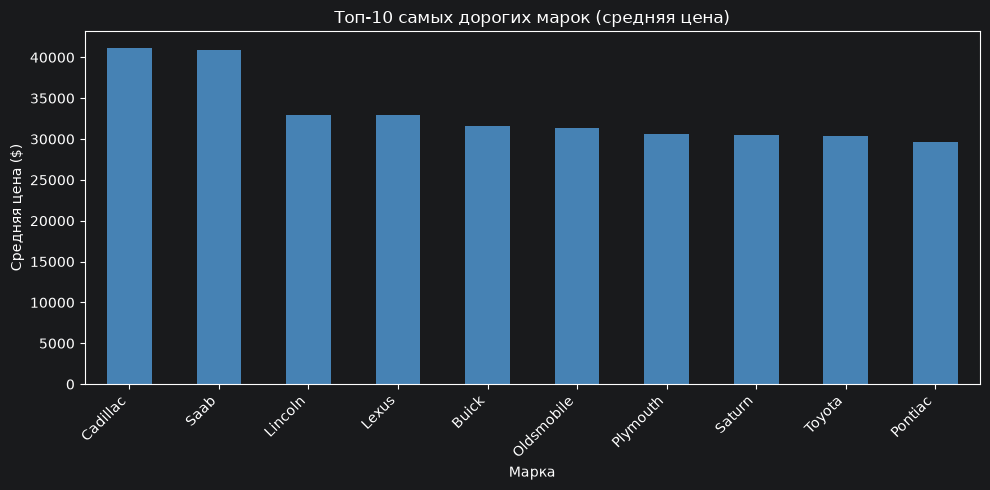

In [5]:
# "Марка" — Company. Считаем среднюю цену по марке.
top10_brands = (
    df.groupby('Company')['Price ($)']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)
print("Топ-10 самых дорогих марок автомобилей (по средней цене):")
print(top10_brands)

# Гистограмма: топ-10 марок по средней цене
top10_brands.plot(kind='bar', figsize=(10, 5), color='steelblue',
                  title='Топ-10 самых дорогих марок (средняя цена)')
plt.ylabel('Средняя цена ($)')
plt.xlabel('Марка')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

5. Найдите среднюю стоимость автомобилей по типам кузова (Body Style), используя метод groupby.

Средняя стоимость автомобилей по типам кузова:
Body Style
Passenger    29845.254130
Sedan        29698.673056
Hardtop      29575.564677
Hatchback    27377.561126
SUV          26729.765799
Name: Price ($), dtype: float64


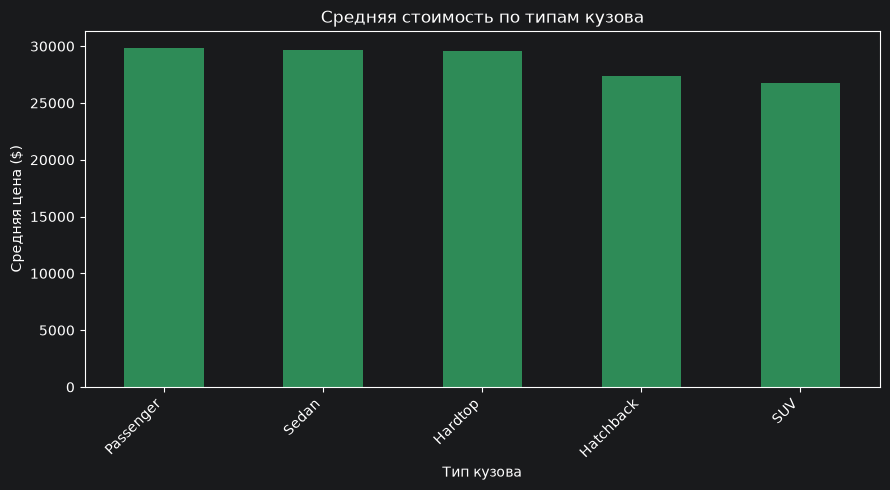

In [6]:
avg_price_by_body = (
    df.groupby('Body Style')['Price ($)']
      .mean()
      .sort_values(ascending=False)
)
print("Средняя стоимость автомобилей по типам кузова:")
print(avg_price_by_body)

# Гистограмма: средняя стоимость по типам кузова
avg_price_by_body.plot(kind='bar', figsize=(9, 5), color='seagreen',
                       title='Средняя стоимость по типам кузова')
plt.ylabel('Средняя цена ($)')
plt.xlabel('Тип кузова')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

6. Какие автомобили приобрели 10 клиентов с самым высоким доходом?

Автомобили 10 клиентов с самым высоким доходом:
Customer Name  Annual Income    Company          Model  Price ($)
       Yaakov        6240000   Chrysler       Concorde      42000
       Athena        5800000   Cadillac       Eldorado      13000
    Francesca        5770000      Volvo            C70      17000
        Fatou        5600000     Nissan     Pathfinder      21000
        Malka        5525000      Volvo            S40      17500
         Mila        5510000  Chevrolet       Corvette      26000
        Judah        5300000    Porsche Carrera Cabrio      32000
        Emily        5110000 Volkswagen            GTI      20000
         Aria        4900000        BMW           528i      25000
       Jazmin        4802500       Ford         Ranger      25251


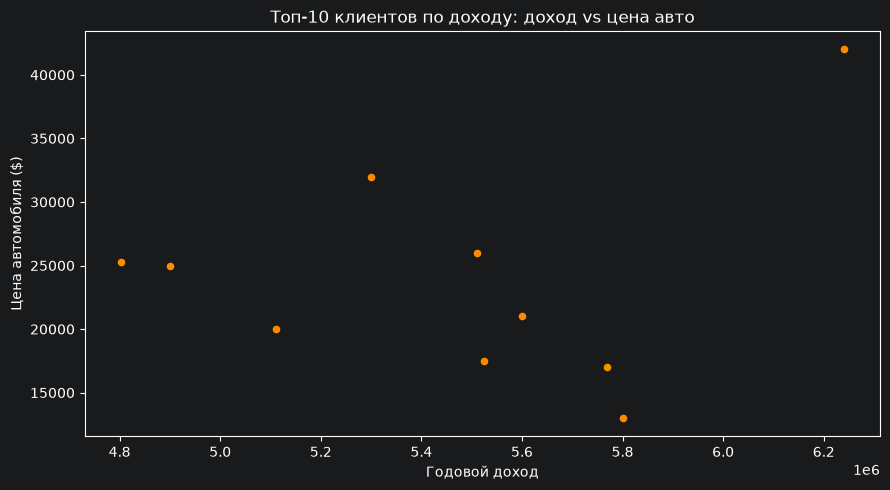

In [7]:
top10_rich = (
    df.sort_values('Annual Income', ascending=False)
      .head(10)[['Customer Name', 'Annual Income', 'Company', 'Model', 'Price ($)']]
)
print("Автомобили 10 клиентов с самым высоким доходом:")
print(top10_rich.to_string(index=False))

# Точечный график: доход vs цена автомобиля для топ-10 богатых клиентов
top10_rich.plot(kind='scatter', x='Annual Income', y='Price ($)', figsize=(9, 5),
                color='darkorange', title='Топ-10 клиентов по доходу: доход vs цена авто')
plt.xlabel('Годовой доход')
plt.ylabel('Цена автомобиля ($)')
plt.tight_layout()
plt.show()

7. Какие автомобили приобрели 10 клиентов с самым низким доходом?


Автомобили 10 клиентов с самым низким доходом:
Customer Name  Annual Income    Company         Model  Price ($)
       Jeremy          13500      Dodge    Ram Pickup      16000
        Anais          13500      Dodge         Viper      26000
     Victoria          13500      Acura            TL      28000
        Heidi          13500    Mercury   Mountaineer      21000
     Benjamin          13500      Dodge         Viper      31000
        Micah          13500 Oldsmobile    Silhouette      19000
        Mason          13500     Nissan      Frontier      20000
     Patricia          13500 Mercedes-B       E-Class      15000
      Quentin          13500    Porsche        Boxter      26000
       Nathan          13500    Porsche Carrera Coupe      26001


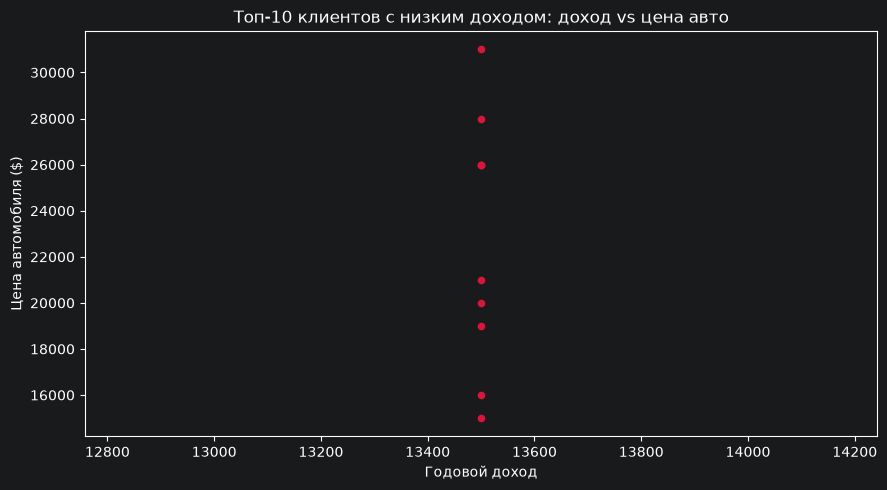

In [8]:
top10_poor = (
    df.sort_values('Annual Income', ascending=True)
      .head(10)[['Customer Name', 'Annual Income', 'Company', 'Model', 'Price ($)']]
)
print("Автомобили 10 клиентов с самым низким доходом:")
print(top10_poor.to_string(index=False))

# Точечный график: доход vs цена автомобиля для топ-10 клиентов с низким доходом
top10_poor.plot(kind='scatter', x='Annual Income', y='Price ($)', figsize=(9, 5),
                color='crimson', title='Топ-10 клиентов с низким доходом: доход vs цена авто')
plt.xlabel('Годовой доход')
plt.ylabel('Цена автомобиля ($)')
plt.tight_layout()
plt.show()

8. Создайте новый столбец, значения которого равны логарифму от величины дохода клиентов.


Датафрейм с новым столбцом Log_Annual_Income:
   Annual Income  Log_Annual_Income
0          13500           9.510519
1        1480000          14.207553
2        1035000          13.849913
3          13500           9.510519
4        1465000          14.197366


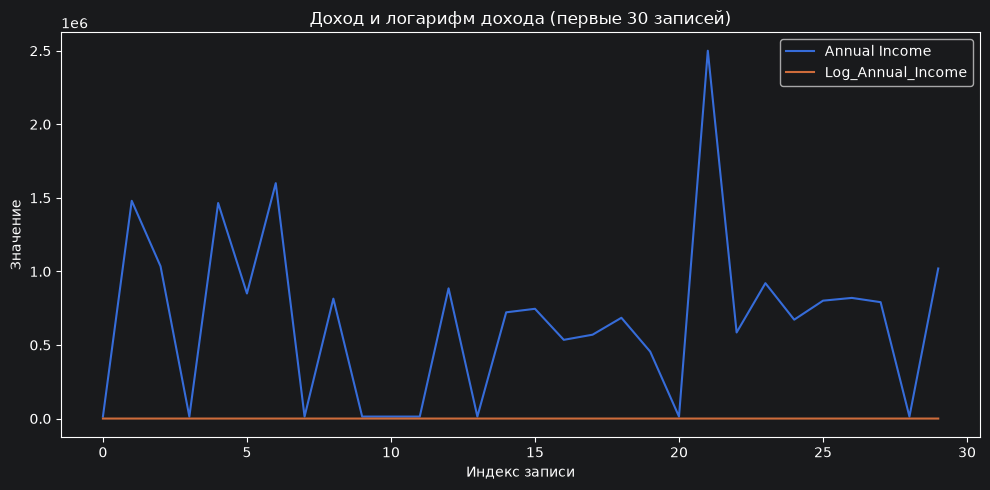

In [9]:
# np.log1p безопасен для нулевых значений (log(1+x))
df['Log_Annual_Income'] = np.log1p(df['Annual Income'])

print("Датафрейм с новым столбцом Log_Annual_Income:")
print(df[['Annual Income', 'Log_Annual_Income']].head())

# Линейный график: исходный доход и его логарифм (первые 30 записей)
df[['Annual Income', 'Log_Annual_Income']].head(30).plot(
    kind='line', figsize=(10, 5), title='Доход и логарифм дохода (первые 30 записей)')
plt.xlabel('Индекс записи')
plt.ylabel('Значение')
plt.tight_layout()
plt.show()